# 05. 분류 — 저평가/고평가 등급 스크리닝

`02_eda_feature_engineering.ipynb`의 `df_fe.parquet`와 `03_regression.ipynb`의 `regression_predictions.parquet`를 불러와 등급 분류 모델을 학습합니다.

**방향**: 회귀 모델의 예측가를 "적정가"로 보고, 실제 거래금액이 예측가 대비 얼마나 벗어났는지(잔차 %)를 기준으로 매물을 **5단계 등급**(적극매수 추천 / 저평가 / 적정가 / 고평가 / 매수주의)으로 나눕니다. 단순 이진분류(저평가 vs 나머지)는 THRESHOLD 경계에서 정보 손실이 크고(-14%와 -16%가 완전히 다르게 분류됨), 실제 서비스에서는 "저평가다/아니다"보다 "어느 정도인지"가 더 유용한 정보이기 때문입니다.

이렇게 만든 등급을 타겟으로, 회귀 예측값 없이 원본 피처(전용면적, 층, 연식, 지역평균가 등)만으로 등급을 직접 예측하는 다중분류 모델을 학습합니다. 신규 매물이 들어왔을 때 회귀 예측 과정 없이도 분류기만으로 바로 등급을 판단할 수 있는지 검증하는 목적입니다.

> 주의: 같은 데이터로 학습한 회귀모델의 잔차로 라벨을 만들기 때문에, 회귀모델 자체가 특정 매물군을 체계적으로 못 맞히면 그 편향이 등급 라벨에도 그대로 들어갑니다. 실전에서는 회귀모델 학습에 안 쓴 홀드아웃 구간의 잔차로 라벨링하는 게 더 안전합니다 (추후 개선점).

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"

df_fe = pd.read_parquet(PROCESSED_DIR / "df_fe.parquet")
pred_df = pd.read_parquet(PROCESSED_DIR / "regression_predictions.parquet")  # 03에서 저장한 예측값

print(df_fe.shape, pred_df.shape)


(6553, 39) (6553, 3)


## 1. 등급 라벨링

`03_regression.ipynb`에서 저장한 예측값(`log_price_pred`)으로 잔차(%)를 계산하고 등급을 매깁니다.

회귀 피처(`X`)를 다시 구성해야 하는데, **`지역평균가`는 `02`에 없는 피처**라 `03`과 똑같은 방식(시간순 분리 후 train 데이터만으로 계산)으로 여기서 다시 만듭니다. 같은 `df_fe`에 같은 로직을 적용하는 거라 `03`에서 만든 `X`와 인덱스가 동일하게 나와서, `pred_df`와 안전하게 join할 수 있습니다.

In [2]:
price_col = "거래금액"

# 03과 동일한 로직으로 지역평균가 재계산 (train 기준, 누수 방지)
base_cols = ["전용면적", "층", "연식", "거래연월", "층_구분", "법정동시군구코드", price_col, "log_price"]
df_base = df_fe[base_cols].dropna().copy()

order = df_base["거래연월"].argsort().to_numpy()
split_idx = int(len(df_base) * 0.8)
train_pos, test_pos = order[:split_idx], order[split_idx:]

df_train_base = df_base.iloc[train_pos].copy()
df_test_base = df_base.iloc[test_pos].copy()

region_mean_train = df_train_base.groupby("법정동시군구코드")[price_col].mean()
global_train_mean = df_train_base[price_col].mean()
df_train_base["지역평균가"] = df_train_base["법정동시군구코드"].map(region_mean_train)
df_test_base["지역평균가"] = df_test_base["법정동시군구코드"].map(region_mean_train).fillna(global_train_mean)

feature_cols = ["전용면적", "층", "연식", "거래연월", "지역평균가"]
cat_cols = ["층_구분"]
df_model = pd.concat([df_train_base, df_test_base], axis=0)
df_model = pd.get_dummies(df_model[feature_cols + cat_cols + ["log_price"]], columns=cat_cols, drop_first=True)

X = df_model.drop(columns=["log_price"])
y = df_model["log_price"]

# pred_df(03에서 저장한 예측값)와 인덱스를 맞춰서 병합
df_grade = X.join(pred_df[["log_price_pred", "is_test"]], how="inner")
y_actual = y.loc[df_grade.index]

residual_pct = (np.expm1(y_actual) - np.expm1(df_grade["log_price_pred"])) / np.expm1(df_grade["log_price_pred"])

def grade(pct):
    if pct < -0.20:
        return "적극매수 추천"
    elif pct < -0.10:
        return "저평가"
    elif pct < 0.10:
        return "적정가"
    elif pct < 0.20:
        return "고평가"
    else:
        return "매수주의"

df_grade["residual_pct"] = residual_pct
df_grade["평가등급"] = residual_pct.apply(grade)

df_grade["평가등급"].value_counts()


평가등급
적정가        5313
고평가         428
저평가         357
매수주의        237
적극매수 추천     218
Name: count, dtype: int64

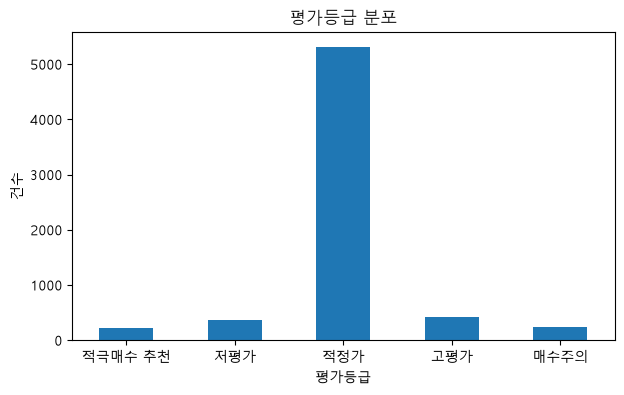

In [3]:
order = ["적극매수 추천", "저평가", "적정가", "고평가", "매수주의"]
df_grade["평가등급"].value_counts().reindex(order).plot(kind="bar", figsize=(7, 4))
plt.title("평가등급 분포")
plt.ylabel("건수")
plt.xticks(rotation=0)
plt.show()


## 2. 분류용 데이터셋 — train/test 분리

회귀와 동일하게 `거래연월` 기준 시간순 분리를 사용합니다 (다른 노트북의 인덱스를 재사용하지 않고 지금 데이터 기준으로 새로 계산 — 이게 이전에 `NameError`/`IndexError`가 반복됐던 원인이었습니다).

In [4]:
X_clf = df_grade[X.columns]  # 회귀와 동일한 피처만 사용 (residual_pct, 평가등급 등은 제외)
y_clf = df_grade["평가등급"]

sort_pos = X_clf["거래연월"].argsort().to_numpy()
split_idx_clf = int(len(X_clf) * 0.8)
train_pos, test_pos = sort_pos[:split_idx_clf], sort_pos[split_idx_clf:]

X_clf_train, X_clf_test = X_clf.iloc[train_pos], X_clf.iloc[test_pos]
y_clf_train, y_clf_test = y_clf.iloc[train_pos], y_clf.iloc[test_pos]

print(X_clf_train.shape, X_clf_test.shape)
y_clf_train.value_counts(normalize=True).round(3)


(5242, 7) (1311, 7)


평가등급
적정가        0.874
저평가        0.052
고평가        0.045
매수주의       0.016
적극매수 추천    0.013
Name: proportion, dtype: float64

## 3. 모델 비교 (다중분류)

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score

clf_models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1, class_weight="balanced"),
}

try:
    from xgboost import XGBClassifier
    clf_models["XGBoost"] = XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        random_state=42, n_jobs=-1, eval_metric="mlogloss"
    )
except ImportError:
    print("xgboost 미설치: pip install xgboost --break-system-packages 후 재실행하면 비교에 포함됩니다.")

clf_results = []
for name, model in clf_models.items():
    model.fit(X_clf_train, y_clf_train)
    pred = model.predict(X_clf_test)
    clf_results.append({
        "model": name,
        "Accuracy": accuracy_score(y_clf_test, pred),
        "F1(macro)": f1_score(y_clf_test, pred, average="macro"),
    })

clf_results_df = pd.DataFrame(clf_results).sort_values("F1(macro)", ascending=False)
clf_results_df


ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1 2 3 4], got ['고평가' '매수주의' '저평가' '적극매수 추천' '적정가']

In [ ]:
best_clf_name = clf_results_df.iloc[0]["model"]
best_clf = clf_models[best_clf_name]
pred_best_clf = best_clf.predict(X_clf_test)

print(f"최종 선택 분류 모델: {best_clf_name}\n")
print(classification_report(y_clf_test, pred_best_clf))


## 미해결 / 보류
- 등급 라벨이 회귀모델 자체의 잔차로 만들어져서, 홀드아웃 기반 라벨링(누수 없는 버전)으로 교체하면 더 안전
- 클래스 불균형(등급별 건수 차이) — 지금은 `class_weight="balanced"`로만 대응, SMOTE 등 추가 기법은 미적용
- **모델(.pkl) 저장 보류** — 피처 확장(지하철역거리 등) 후 최종 확정 시 저장 예정

## 다음 단계
회귀·군집·분류 세 노트북 모두 일단 베이스라인이 완성되었습니다. 이제 지하철역거리·학군 등 피처를 `02_eda_feature_engineering.ipynb`에 추가하고, `03`→`04`→`05` 순서로 다시 실행해서 성능/구조 변화를 비교하면 됩니다.